# Find broadband mags for Uchuu UM galaxies

### This is a notebook to take in a spectral template and measure the broadband magnitudes for a filter set

The Uchuu UM galaxy catalog gives a value for M$_{\rm UV,1500A}$ for each galaxy in the snapshot box. I have included a subset of galaxies from one of the snapshot boxes with a redshift (z) determined by their position within the box assuming the plane-parallel distant-observer approximation.

The necessary files are in the data directory of this repository:
CFHT_MegaCam.u_1.dat
CFHT_MegaCam.g_1.dat
CFHT_MegaCam.r_1.dat
MUSYC_LBGonly_stackEXT.fits
Uchuu_UM_z2p95_MuvCUT_BOX.fits

In [1]:
#PACKAGES
from astropy.table import Table
import matplotlib.pyplot as plt
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u
import numpy as np
from astropy.io import fits
from scipy.interpolate import interp1d,InterpolatedUnivariateSpline

In [2]:
#DEFINITIONS

c = 2.99792458e18  # Angstrom/s

def pSS(TEXT):
    Label = r'{}'.format(TEXT)
    Labela='\\rm {}'.format(Label)
    Labela='{'+Labela+'}'
    return Labela

def compute_ab_mag(wavelength_A, flux_lambda, filter_wavelength_A, filter_transmission):
    FLTcen = np.sqrt(np.trapz(y=filter_transmission*filter_wavelength_A,x=filter_wavelength_A)/np.trapz(y=filter_transmission/filter_wavelength_A,x=filter_wavelength_A)) #Pivot Wavelength https://pysynphot.readthedocs.io/en/latest/properties.html#pysynphot-formula-qtlam
    intFLT = InterpolatedUnivariateSpline(filter_wavelength_A, filter_transmission, k=4)
    FLTtrans_fun = lambda s: intFLT(s)

    cut1 = wavelength_A >= filter_wavelength_A.min()
    cut2 = wavelength_A <= filter_wavelength_A.max()
    wavelength_A = wavelength_A[cut1*cut2]
    flux_lambda = flux_lambda[cut1*cut2]

    FLTlam =np.trapz(y=flux_lambda*wavelength_A*FLTtrans_fun(wavelength_A),x=wavelength_A)/np.trapz(y=wavelength_A*FLTtrans_fun(wavelength_A),x=wavelength_A) #Koornneef, J., Bohlin, R., Buser, R., Horne, K., & Turnshek, D. 1986, Highlights Astron., 7, 833  
    FLTJy =  FLTlam* ((FLTcen)**2/c)/1E-23
    if FLTJy<=0:
        FLTmag = -99
    else:
        FLTmag=-1.0*(np.log10(1e6*FLTJy)*2.5-23.9)
    return FLTmag,FLTlam

def mag2flux(Muv, z, lambda_ref=1500.0, cosmology=[]):
    # Compute luminosity distance in pc
    DL = cosmology.luminosity_distance(z).to('pc').value  # from astropy in physical units

    m_obs = Muv + 5*np.log10(DL/10)-2.5*np.log10((1+z)) # Kcorr for blueshifted filter, https://kcorrect.readthedocs.io/en/5.1.2/basics.html

    # Convert apparent AB magnitude to f_nu (erg/s/cm^2/Hz)
    f_nu = 10**(-(m_obs + 48.6) / 2.5)

    # Convert f_nu to f_lambda (erg/s/cm^2/Å)
    lambda_obs = lambda_ref * (1 + z)  # Observed wavelength
    f_lambda = f_nu * c / (lambda_obs**2)
    return f_lambda

In [3]:
#Global Variables

ROOT = '/Users/ave_astro/Desktop/IPMU/PFS'
DATAdir = 'Uchuu/data'
UMdir = 'Uchuu/UM'
PLOT = False
output_dir = "{}/{}".format(ROOT,DATAdir)

# Uchuu uses the following cosmology: 
# Planck2015 (table 4, rightmost column)
#Ω_m = 0.3089 Ω_L = 0.6911 h = 0.6774
#σ_8 = 0.8159 Ω_b = 0.0486 ns = 0.9667
#Linear Power Spectrum
#z_init = 127 (2LPT)
## Uchuu is 2000 Mpc/h on a side 
Om0 = 0.3089
h = 0.6774
H0 = 100*h
Lbox = 2000 # Mpc/h
ns = 0.9667
sigma8 = 0.8159
Ob0 = 0.0486
Tcmb0 = 2.718
Ucosmo = FlatLambdaCDM(H0=H0, Om0=Om0, Ob0=Ob0, Tcmb0=2.718 * u.K)

In [4]:
#Filter set and LBG spectra template
wave_u,trans_u = np.loadtxt('{}/{}/CFHT_MegaCam.u_1.dat'.format(ROOT,DATAdir),unpack=True)
wave_g,trans_g = np.loadtxt('{}/{}/CFHT_MegaCam.g_1.dat'.format(ROOT,DATAdir),unpack=True)
wave_r,trans_r = np.loadtxt('{}/{}/CFHT_MegaCam.r_1.dat'.format(ROOT,DATAdir),unpack=True)

filters = {
    'mc_u': (wave_u, trans_u),
    'mc_g': (wave_g, trans_g),
    'mc_r': (wave_r, trans_r),
}


keys = list(filters.keys())
FILTcen = []
FILTwid = []
for i in range(0,len(keys)):
    FILTcen.append(np.sqrt(np.trapz(y=filters[keys[i]][1]*filters[keys[i]][0],x=filters[keys[i]][0])/np.trapz(y=filters[keys[i]][1]/filters[keys[i]][0],x=filters[keys[i]][0])))
    lam0 = np.trapz(y=filters[keys[i]][1]*filters[keys[i]][0],x=filters[keys[i]][0])/np.trapz(y=filters[keys[i]][1],x=filters[keys[i]][0])
    FILTwid.append(np.sqrt(np.trapz(y=filters[keys[i]][1]*(filters[keys[i]][0]-lam0)**2,x=filters[keys[i]][0])/np.trapz(y=filters[keys[i]][1],x=filters[keys[i]][0])))

LBGsed = fits.open('{}/{}/MUSYC_LBGonly_stackEXT.fits'.format(ROOT,DATAdir))
waveTEMP = LBGsed[1].data['wavelength']
flux_LBG = LBGsed[1].data['flux']

In [5]:
# Galaxy Catalog
catUM = Table.read('{}/{}/Uchuu_UM_z2p95_MuvCUT_BOX.fits'.format(ROOT,DATAdir))
idUM = catUM['ID']
MuvUM = catUM['Muv']
zUM = catUM['z']
Ngal = len(zUM)

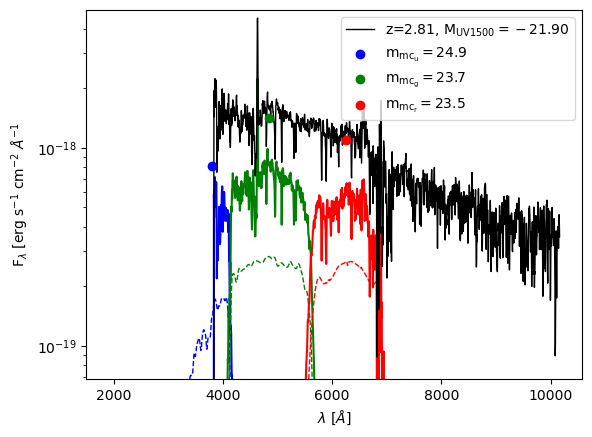

In [6]:
## MAIN ##
u_gal = []
g_gal = []
r_gal = []
for ii in range(0,Ngal):
    wave_obs = waveTEMP * (1 + zUM[ii])
    flux_LBGint = interp1d(wave_obs, flux_LBG, bounds_error=False, fill_value="extrapolate")
    lamMuvOBS = 1500.0 * (1 + zUM[ii])

    # Scale SED
    Flam_MuvOBS = mag2flux(MuvUM[ii],zUM[ii],cosmology=Ucosmo)
    Fsed = flux_LBGint(lamMuvOBS)
    scale = Flam_MuvOBS / Fsed
    FobsSCALE = flux_LBG * scale

    # Measure broadband mags and f_lam
    magTMP = {f: compute_ab_mag(wave_obs, FobsSCALE, filt[0], filt[1])for f, filt in filters.items()}
    u_gal.append(magTMP['mc_u'][0])
    g_gal.append(magTMP['mc_g'][0])
    r_gal.append(magTMP['mc_r'][0])

    if ii == 0:
        plt.plot(wave_obs,FobsSCALE,color='k',zorder=3,lw=1,label=r'z={}, M$_{}={}$'.format(str(zUM[ii])[:4],pSS('UV1500'),str(MuvUM[ii])[:6]))
        colors = ['b','g','r']
        for i in range(0,len(keys)):
            plt.scatter(FILTcen[i],magTMP[keys[i]][1],zorder=4,color=colors[i],label=r'm$_{}={}$'.format(pSS(keys[i]),str(magTMP[keys[i]][0])[:4]))
            waveFLT = filters[keys[i]][0]
            tranFLT = filters[keys[i]][1]
            intFLT = InterpolatedUnivariateSpline(waveFLT,tranFLT,k=4)
            FLTtrans_fun = lambda s: intFLT(s)
            cut1 = wave_obs < waveFLT.max()
            cut2 = wave_obs > waveFLT.min()
            #waveDIF = ((wave_obs[1:]-wave_obs[:-1]))[0]
            #Flam = (FobsSCALE[cut1*cut2]*waveDIF).sum()/FILTwid[0]
            #print('FluxSUM {}  HSTavg {}'.format(Flam,magTMP[keys[i]][1]))
            plt.plot(wave_obs[cut1*cut2],FobsSCALE[cut1*cut2]*FLTtrans_fun(wave_obs[cut1*cut2]),color=colors[i])
            plt.plot(filters[keys[i]][0],filters[keys[i]][1]*FobsSCALE.mean()*0.8,lw=1,ls='--',color=colors[i])
        plt.ylim(FobsSCALE.mean()*0.1,FobsSCALE.max()*1.1)
        plt.yscale('log')
        plt.ylabel(r'F$_\lambda$ [erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$',fontsize=10)
        plt.xlabel(r'$\lambda$ [$\AA$]',fontsize=10)
        plt.legend(loc='upper right',fontsize=10)
        plt.show()

In [7]:
# Save Output
u_gal = np.array(u_gal)
g_gal = np.array(g_gal)
r_gal = np.array(r_gal)

catUM['u'] = u_gal
catUM['g'] = g_gal
catUM['r'] = r_gal

catUM.write('{}/{}/Uchuu_UM_z2p95_MuvCUT_BOX_wMAG.fits'.format(ROOT,DATAdir),format='fits',overwrite=True)

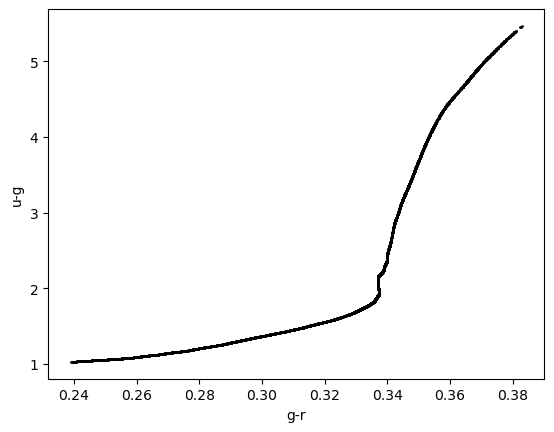

In [8]:
# Plot color-color
plt.scatter(g_gal-r_gal,u_gal-g_gal,color='k',s=1)
plt.ylabel(r'u-g')
plt.xlabel(r'g-r')
plt.show()

A new .fits file is output with the new broadbang mags appended. My output for this (Uchuu_UM_z2p95_MuvCUT_BOX_wMAG.fits) is included in the data directory of this repository.